# BÀI KIỂM TRA GIỮA KỲ: HỌC MÁY VÀ ỨNG DỤNG
## Họ và tên: Hà Trần Khánh Huy - MSSV: 102230018 - Lớp: 23T_NHAT1

## Đề số 04

1. **Câu 1 - PCA:** giảm chiều dữ liệu bảng với số chiều đầu vào `D >= 7` và số chiều đầu ra `k <= 4`, sau đó trực quan hóa.
2. **Câu 2 - Fuzzy C-Means:** phân cụm mờ với ít nhất 5 cụm; tự cài đặt từng bước, đối chiếu với `scikit-fuzzy` và trực quan hóa.
3. **Câu 3 - Phân đoạn ảnh màu:** chọn một ảnh từ CBSD68, phân đoạn với ít nhất 3 nhóm màu; so sánh K-Means tự cài đặt với `scikit-learn`.

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import os
import time

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import skfuzzy as fuzz

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)

print("Tải thành công các thư viện cần thiết!")


Tải thành công các thư viện cần thiết!


## TIỀN XỬ LÝ DỮ LIỆU BẢNG

Chuẩn bị dữ liệu dùng chung cho Câu 1 và Câu 2.

- Đọc `data/wine.csv`, trong đó cột `Wine` là nhãn và các cột còn lại là đặc trưng số.
- Kiểm tra kích thước, tên đặc trưng và giá trị thiếu.
- Chuẩn hóa từng đặc trưng bằng Z-score:
  
  `z = (x - mu) / sigma`

- Việc chuẩn hóa là cần thiết vì các đặc trưng có đơn vị và độ lớn rất khác nhau, ví dụ `Proline` lớn hơn nhiều so với `Hue`.
- Ma trận sau chuẩn hóa có dạng `X in R^(N x D)`, với `D = 13 >= 7`, thỏa điều kiện của đề.


In [80]:
DATA_PATH = 'data/wine.csv'

df_raw = pd.read_csv(DATA_PATH)
print(f"-> Nạp dữ liệu: {DATA_PATH}")
print(f"-> Kích thước thô: {df_raw.shape[0]} dòng, {df_raw.shape[1]} cột")

LABEL_COL = 'Wine'
FEATURE_COLS = [c for c in df_raw.columns if c != LABEL_COL]
D_IN = len(FEATURE_COLS)

print(f"-> Số chiều đầu vào D = {D_IN}")
for idx, col in enumerate(FEATURE_COLS, 1):
    print(f"   {idx:2d}. {col}")


X_raw = df_raw[FEATURE_COLS].to_numpy(dtype=float)
mu_X = np.mean(X_raw, axis=0)
sigma_X = np.std(X_raw, axis=0, ddof=0)
sigma_X[sigma_X == 0] = 1.0

X = (X_raw - mu_X) / sigma_X
N, D = X.shape

print(f"\n-> Kích thước ma trận sau chuẩn hóa X: {N} dòng x {D} cột")
print(f"-> Phân bố nhãn các nhóm rượu (cột '{LABEL_COL}'):\n{df_raw[LABEL_COL].value_counts().sort_index()}")

df_raw[FEATURE_COLS].describe().T[['mean', 'std', 'min', '50%', 'max']]


-> Nạp dữ liệu: data/wine.csv
-> Kích thước thô: 178 dòng, 14 cột
-> Số chiều đầu vào D = 13
    1. Alcohol
    2. Malic.acid
    3. Ash
    4. Acl
    5. Mg
    6. Phenols
    7. Flavanoids
    8. Nonflavanoid.phenols
    9. Proanth
   10. Color.int
   11. Hue
   12. OD
   13. Proline

-> Kích thước ma trận sau chuẩn hóa X: 178 dòng x 13 cột
-> Phân bố nhãn các nhóm rượu (cột 'Wine'):
Wine
1    59
2    71
3    48
Name: count, dtype: int64


,mean,std,min,50%,max
Alcohol,13.0006,0.8118,11.03,13.050,14.83
Malic.acid,2.3363,1.1171,0.74,1.865,5.80
Ash,2.3665,0.2743,1.36,2.360,3.23
Acl,19.4949,3.3396,10.60,19.500,30.00
Mg,99.7416,14.2825,70.00,98.000,162.00
Phenols,2.2951,0.6259,0.98,2.355,3.88
Flavanoids,2.0293,0.9989,0.34,2.135,5.08
Nonflavanoid.phenols,0.3619,0.1245,0.13,0.340,0.66
Proanth,1.5909,0.5724,0.41,1.555,3.58
Color.int,5.0581,2.3183,1.28,4.690,13.00


# CÂU 1: GIẢM CHIỀU DỮ LIỆU BẰNG PCA

### Mục tiêu

Tìm một không gian con có số chiều `k <= 4` nhưng vẫn giữ được nhiều phương sai nhất của dữ liệu chuẩn hóa.

### Quy trình PCA tự cài đặt

1. Trừ trung bình để thu được `X_centered`.
2. Tính ma trận hiệp phương sai `S = X_centered.T @ X_centered / (N - 1)`.
3. Phân rã trị riêng của `S` bằng `np.linalg.eigh`.
4. Sắp xếp trị riêng giảm dần; các vector riêng tương ứng là các hướng PCA.
5. Chọn `K_PCA = 2` và lập ma trận chiếu `W` gồm hai vector riêng đầu tiên.
6. Chiếu dữ liệu: `Y = X_centered @ W`.

Tỷ lệ phương sai giải thích của thành phần thứ `i` là `EVR_i = lambda_i / sum(lambda)`. Scree plot và EVR tích lũy giúp đánh giá lượng thông tin được giữ lại.


In [81]:
# CÂU 1: PHƯƠNG PHÁP 1 - PCA MA TRẬN HIỆP PHƯƠNG SAI

mean_vec = np.mean(X, axis=0)
X_centered = X - mean_vec

cov_matrix = np.dot(X_centered.T, X_centered) / (N - 1)

eigenvals_cov, eigenvecs_cov = np.linalg.eigh(cov_matrix)

sort_idx = np.argsort(eigenvals_cov)[::-1]
eigenvals_cov = eigenvals_cov[sort_idx]
eigenvecs_cov = eigenvecs_cov[:, sort_idx]

evr_cov = eigenvals_cov / np.sum(eigenvals_cov)
cum_evr_cov = np.cumsum(evr_cov)

K_PCA = 2  # k = 2 <= 4

W_cov = eigenvecs_cov[:, :K_PCA]

Y_cov = np.dot(X_centered, W_cov)

df_pca_summary = pd.DataFrame({
    'Thành phần': [f'PC{i+1}' for i in range(D)],
    'Trị riêng (Eigenvalue)': np.round(eigenvals_cov, 4),
    'Tỷ lệ EVR': np.round(evr_cov, 4),
    'Tỷ lệ EVR (%)': [f'{v*100:.2f}%' for v in evr_cov],
    'Tích lũy EVR': np.round(cum_evr_cov, 4),
    'Tích lũy (%)': [f'{v*100:.2f}%' for v in cum_evr_cov]
})

print("=== BẢNG TỔNG HỢP TOÀN BỘ 13 THÀNH PHẦN CHÍNH (PCA COVARIANCE) ===")
print(df_pca_summary.to_string(index=False))

print(f"\n-> LỰA CHỌN SỐ CHIỀU ĐẦU RA k = {K_PCA} (Thỏa mãn điều kiện k <= 4):")
print(f"   + PC1 giải thích : {evr_cov[0]*100:.2f}% phương sai")
print(f"   + PC2 giải thích : {evr_cov[1]*100:.2f}% phương sai")
print(f"   + Tích lũy 2 chiều: {cum_evr_cov[K_PCA-1]*100:.2f}% tổng phương sai của 13 đặc trưng gốc")
print(f"   + Nếu lấy k = 3 hoặc k = 4 chiều (vẫn <= 4), lượng phương sai tích lũy lần lượt đạt {cum_evr_cov[2]*100:.2f}% và {cum_evr_cov[3]*100:.2f}%")


=== BẢNG TỔNG HỢP TOÀN BỘ 13 THÀNH PHẦN CHÍNH (PCA COVARIANCE) ===
Thành phần  Trị riêng (Eigenvalue)  Tỷ lệ EVR Tỷ lệ EVR (%)  Tích lũy EVR Tích lũy (%)
       PC1                  4.7324     0.3620        36.20%        0.3620       36.20%
       PC2                  2.5111     0.1921        19.21%        0.5541       55.41%
       PC3                  1.4542     0.1112        11.12%        0.6653       66.53%
       PC4                  0.9242     0.0707         7.07%        0.7360       73.60%
       PC5                  0.8580     0.0656         6.56%        0.8016       80.16%
       PC6                  0.6453     0.0494         4.94%        0.8510       85.10%
       PC7                  0.5541     0.0424         4.24%        0.8934       89.34%
       PC8                  0.3505     0.0268         2.68%        0.9202       92.02%
       PC9                  0.2905     0.0222         2.22%        0.9424       94.24%
      PC10                  0.2523     0.0193         1.93%    

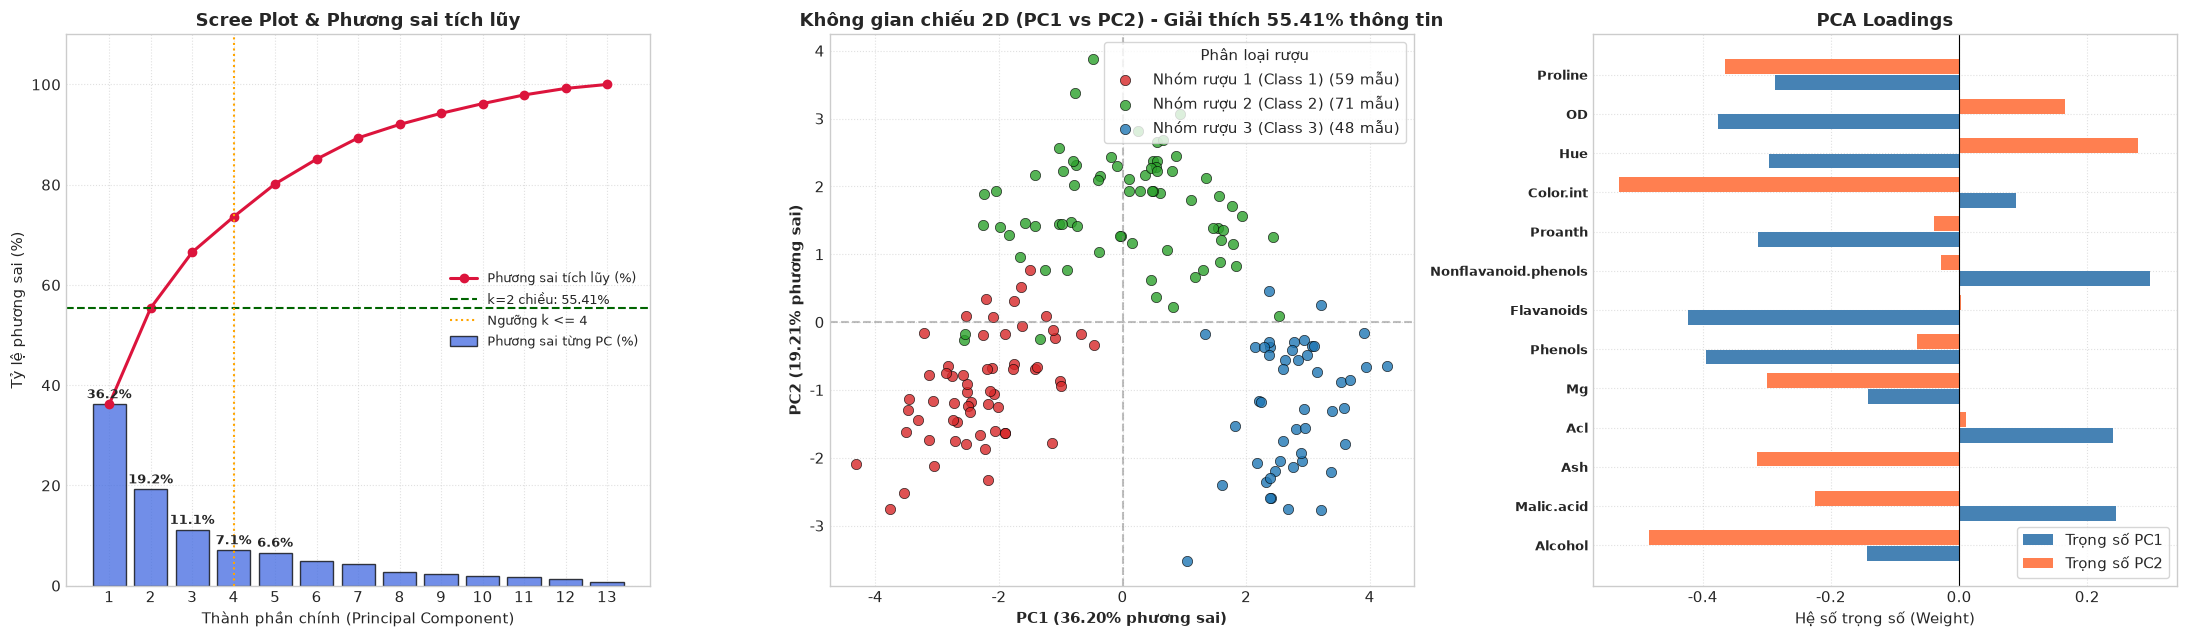

In [82]:
# CÂU 1: TRỰC QUAN HÓA KẾT QUẢ PCA

fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))

# SCREE PLOT & CUMULATIVE VARIANCE

bars = axes[0].bar(range(1, D + 1), evr_cov * 100, color='royalblue', alpha=0.75, edgecolor='black', label='Phương sai từng PC (%)')
axes[0].plot(range(1, D + 1), cum_evr_cov * 100, color='crimson', marker='o', linewidth=2.2, label='Phương sai tích lũy (%)')
axes[0].axhline(y=cum_evr_cov[K_PCA - 1] * 100, color='darkgreen', linestyle='--', linewidth=1.5,
                label=f'k={K_PCA} chiều: {cum_evr_cov[K_PCA - 1]*100:.2f}%')
axes[0].axvline(x=4, color='orange', linestyle=':', linewidth=1.5, label='Ngưỡng k <= 4')

for i in range(min(5, D)):
    axes[0].text(i + 1, evr_cov[i] * 100 + 1.2, f'{evr_cov[i]*100:.1f}%', ha='center', fontsize=9, fontweight='bold')

axes[0].set_title('Scree Plot & Phương sai tích lũy', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Thành phần chính (Principal Component)')
axes[0].set_ylabel('Tỷ lệ phương sai (%)')
axes[0].set_xticks(range(1, D + 1))
axes[0].set_ylim(0, 110)
axes[0].legend(loc='center right', fontsize=9.5)
axes[0].grid(True, linestyle=':', alpha=0.6)


labels = df_raw[LABEL_COL].values
unique_labels = np.unique(labels)
wine_colors = {1: '#d62728', 2: '#2ca02c', 3: '#1f77b4'}
wine_names = {1: 'Nhóm rượu 1 (Class 1)', 2: 'Nhóm rượu 2 (Class 2)', 3: 'Nhóm rượu 3 (Class 3)'}

for lbl in unique_labels:
    mask = (labels == lbl)
    axes[1].scatter(
        Y_cov[mask, 0], Y_cov[mask, 1],
        c=wine_colors[lbl], label=f"{wine_names[lbl]} ({np.sum(mask)} mẫu)",
        alpha=0.8, edgecolors='k', linewidth=0.5, s=55
    )

axes[1].set_title(f'Không gian chiếu 2D (PC1 vs PC2) - Giải thích {cum_evr_cov[1]*100:.2f}% thông tin', fontsize=13, fontweight='bold')
axes[1].set_xlabel(f'PC1 ({evr_cov[0]*100:.2f}% phương sai)', fontsize=11, fontweight='bold')
axes[1].set_ylabel(f'PC2 ({evr_cov[1]*100:.2f}% phương sai)', fontsize=11, fontweight='bold')
axes[1].axhline(0, color='gray', linestyle='--', alpha=0.5)
axes[1].axvline(0, color='gray', linestyle='--', alpha=0.5)
axes[1].legend(title='Phân loại rượu', loc='upper right', frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)


y_pos = np.arange(len(FEATURE_COLS))
axes[2].barh(y_pos - 0.2, W_cov[:, 0], height=0.38, color='steelblue', label='Trọng số PC1')
axes[2].barh(y_pos + 0.2, W_cov[:, 1], height=0.38, color='coral', label='Trọng số PC2')
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels(FEATURE_COLS, fontsize=9.5, fontweight='bold')
axes[2].axvline(0, color='black', linewidth=0.8)
axes[2].set_title('PCA Loadings', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Hệ số trọng số (Weight)')
axes[2].legend(loc='lower right', frameon=True)
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [83]:
# ĐỐI CHIẾU VỚI THƯ VIỆN SCIKIT-LEARN (PCA)

pca_sklearn = PCA(n_components=K_PCA)
Y_sklearn = pca_sklearn.fit_transform(X)

diff_evr = np.max(np.abs(evr_cov[:K_PCA] - pca_sklearn.explained_variance_ratio_))

diff_proj_sk = np.max(np.abs(np.abs(Y_cov) - np.abs(Y_sklearn)))

df_pca_comp = pd.DataFrame({
    'Thành phần': [f"PC{i+1}" for i in range(K_PCA)],
    'EVR From Scratch': np.round(evr_cov[:K_PCA], 6),
    'EVR Scikit-Learn': np.round(pca_sklearn.explained_variance_ratio_, 6),
    'Chênh lệch tuyệt đối': [f"{v:.4e}" for v in np.abs(evr_cov[:K_PCA] - pca_sklearn.explained_variance_ratio_)]
})

print("=== SO SÁNH: PCA TỰ CÀI ĐẶT vs SCIKIT-LEARN ===")
print(df_pca_comp.to_string(index=False))
print(f"\n-> Độ sai lệch EVR cực đại     : {diff_evr:.4e}")
print(f"-> Độ sai lệch tọa độ chiếu cực đại: {diff_proj_sk:.4e}")

=== SO SÁNH: PCA TỰ CÀI ĐẶT vs SCIKIT-LEARN ===
Thành phần  EVR From Scratch  EVR Scikit-Learn Chênh lệch tuyệt đối
       PC1            0.3620            0.3620           0.0000e+00
       PC2            0.1921            0.1921           0.0000e+00

-> Độ sai lệch EVR cực đại     : 0.0000e+00
-> Độ sai lệch tọa độ chiếu cực đại: 3.1086e-15


---
# CÂU 2: PHÂN CỤM DỮ LIỆU BẰNG FUZZY C-MEANS & TRỰC QUAN KẾT QUẢ

---

In [84]:
# CÂU 2: CÀI ĐẶT THUẬT TOÁN FUZZY C-MEANS TỪNG BƯỚC

N_CLUSTERS = 5       # Số cụm C >= 5 (đề ghi m >= 5)
FUZZIFIER_M = 2.0    # Tham số mờ hóa m
MAX_ITER = 150       # Số vòng lặp tối đa
TOLERANCE = 1e-5     # Ngưỡng hội tụ epsilon
RANDOM_STATE = 42

def fcm_step_scratch(X, U, m=2.0):
    """
    Thực hiện 1 bước lặp của Fuzzy C-Means From Scratch:
    Đầu vào: X (N x D), U (N x C), m (tham số mờ)
    Đầu ra : Tâm V (C x D), new_U (N x C), dists (N x C), J_m (hàm mục tiêu)
    """
    N, D = X.shape
    C = U.shape[1]
    
    # 1. Cập nhật tâm cụm V
    U_m = U ** m
    sum_U_m = np.sum(U_m, axis=0)
    V = np.dot(U_m.T, X) / (sum_U_m[:, None] + 1e-12)
    
    # 2. Tính khoảng cách Euclidean
    diff = X[:, None, :] - V[None, :, :]
    dists = np.sqrt(np.sum(diff ** 2, axis=2))
    
    # 3. Cập nhật độ thuộc new_U
    new_U = np.zeros_like(U)
    power = 2.0 / (m - 1.0)
    
    for i in range(N):
        d_i = dists[i]
        zero_mask = (d_i < 1e-10)
        if np.any(zero_mask):
            new_U[i, :] = 0.0
            new_U[i, zero_mask] = 1.0 / np.sum(zero_mask)
        else:
            ratios = (d_i[:, None] / d_i[None, :]) ** power
            new_U[i, :] = 1.0 / np.sum(ratios, axis=1)
            
    # 4. Tính hàm mục tiêu J_m
    J_m = np.sum((new_U ** m) * (dists ** 2))
    return V, new_U, dists, J_m

class FuzzyCMeansScratch:
    def __init__(self, n_clusters=5, m=2.0, max_iter=150, tol=1e-5, random_state=42):
        self.n_clusters = n_clusters
        self.m = m
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centers = None
        self.u = None
        self.fpc = None
        self.history = []
        
    def fit(self, X, init_u=None):
        N, D = X.shape
        C = self.n_clusters
        
        # Khởi tạo ma trận độ thuộc U
        if init_u is None:
            np.random.seed(self.random_state)
            self.u = np.random.dirichlet(np.ones(C), size=N)
        else:
            self.u = init_u.copy()
            
        print(f"=== TIẾN TRÌNH LẶP FUZZY C-MEANS (C={C}, m={self.m}) ===")
        print(f"{'Vòng lặp':^10} | {'Delta U':^14} | {'Hàm mục tiêu J_m':^18} | {'FPC':^10}")
        print("-" * 60)
        
        for it in range(1, self.max_iter + 1):
            V, new_u, dists, J_m = fcm_step_scratch(X, self.u, m=self.m)
            delta_u = np.max(np.abs(new_u - self.u))
            fpc_cur = np.sum(new_u ** 2) / N
            
            self.history.append({'iteration': it, 'delta_u': delta_u, 'J_m': J_m, 'fpc': fpc_cur})
            
            print(f"{it:^10d} | {delta_u:^14.6f} | {J_m:^18.4f} | {fpc_cur:^10.4f}")
                
            if delta_u < self.tol:
                print("-" * 60)
                print(f"--> Thuật toán đã HỘI TỤ THÀNH CÔNG tại vòng lặp thứ {it} (Delta U < {self.tol})!")
                break
                
            self.u = new_u
            
        self.centers = V
        self.u = new_u
        self.fpc = np.sum(self.u ** 2) / N
        return self
        
    def predict_hard_clusters(self):
        return np.argmax(self.u, axis=1)

np.random.seed(RANDOM_STATE)
INITIAL_U = np.random.dirichlet(np.ones(N_CLUSTERS), size=N)

fcm_scratch = FuzzyCMeansScratch(n_clusters=N_CLUSTERS, m=FUZZIFIER_M, max_iter=MAX_ITER, tol=TOLERANCE, random_state=RANDOM_STATE)
fcm_scratch.fit(X, init_u=INITIAL_U)

print(f"\n-> Chỉ số phân hoạch mờ FPC (From Scratch): {fcm_scratch.fpc:.6f}")

df_centers_z = pd.DataFrame(fcm_scratch.centers, columns=FEATURE_COLS, index=[f"Tâm {k}" for k in range(N_CLUSTERS)])
print("\n=== TỌA ĐỘ CÁC TÂM MỜ (KHÔNG GIAN CHUẨN HÓA Z-SCORE) ===")
print(df_centers_z)

centers_real = fcm_scratch.centers * sigma_X + mu_X
df_centers_real = pd.DataFrame(centers_real, columns=FEATURE_COLS, index=[f"Tâm {k}" for k in range(N_CLUSTERS)])
print("\n=== TỌA ĐỘ CÁC TÂM MỜ  ===")
df_centers_real


=== TIẾN TRÌNH LẶP FUZZY C-MEANS (C=5, m=2.0) ===
 Vòng lặp  |    Delta U     |  Hàm mục tiêu J_m  |    FPC    
------------------------------------------------------------
    1      |    0.573443    |      465.0007      |   0.2012  
    2      |    0.032149    |      462.4324      |   0.2012  
    3      |    0.032083    |      461.6926      |   0.2022  
    4      |    0.052486    |      460.4465      |   0.2044  
    5      |    0.074636    |      458.2276      |   0.2087  
    6      |    0.081193    |      454.8746      |   0.2158  
    7      |    0.078563    |      451.0707      |   0.2250  
    8      |    0.065248    |      447.9285      |   0.2339  
    9      |    0.049233    |      445.5177      |   0.2414  
    10     |    0.071768    |      443.0053      |   0.2485  
    11     |    0.092450    |      439.9859      |   0.2563  
    12     |    0.091765    |      437.1740      |   0.2643  
    13     |    0.069993    |      435.4776      |   0.2704  
    14     |    0.042

,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
Tâm 0,12.6580,2.1281,2.3171,19.8281,96.6707,2.2614,2.0399,0.3607,1.5795,4.0456,1.0036,2.7086,638.6539
Tâm 1,13.1428,3.3958,2.4085,21.1465,97.9106,1.7182,0.8915,0.4527,1.1904,7.1640,0.7109,1.7914,638.6848
Tâm 2,13.7355,1.9122,2.4280,17.2133,106.6489,2.8709,2.9839,0.2881,1.9511,5.8228,1.0514,3.1043,1110.9650
Tâm 3,12.6587,2.1280,2.3172,19.8255,96.6816,2.2621,2.0409,0.3606,1.5799,4.0467,1.0037,2.7091,638.9897
Tâm 4,12.7033,2.1242,2.3237,19.6862,97.3120,2.3006,2.0951,0.3539,1.6033,4.1126,1.0080,2.7349,659.1349


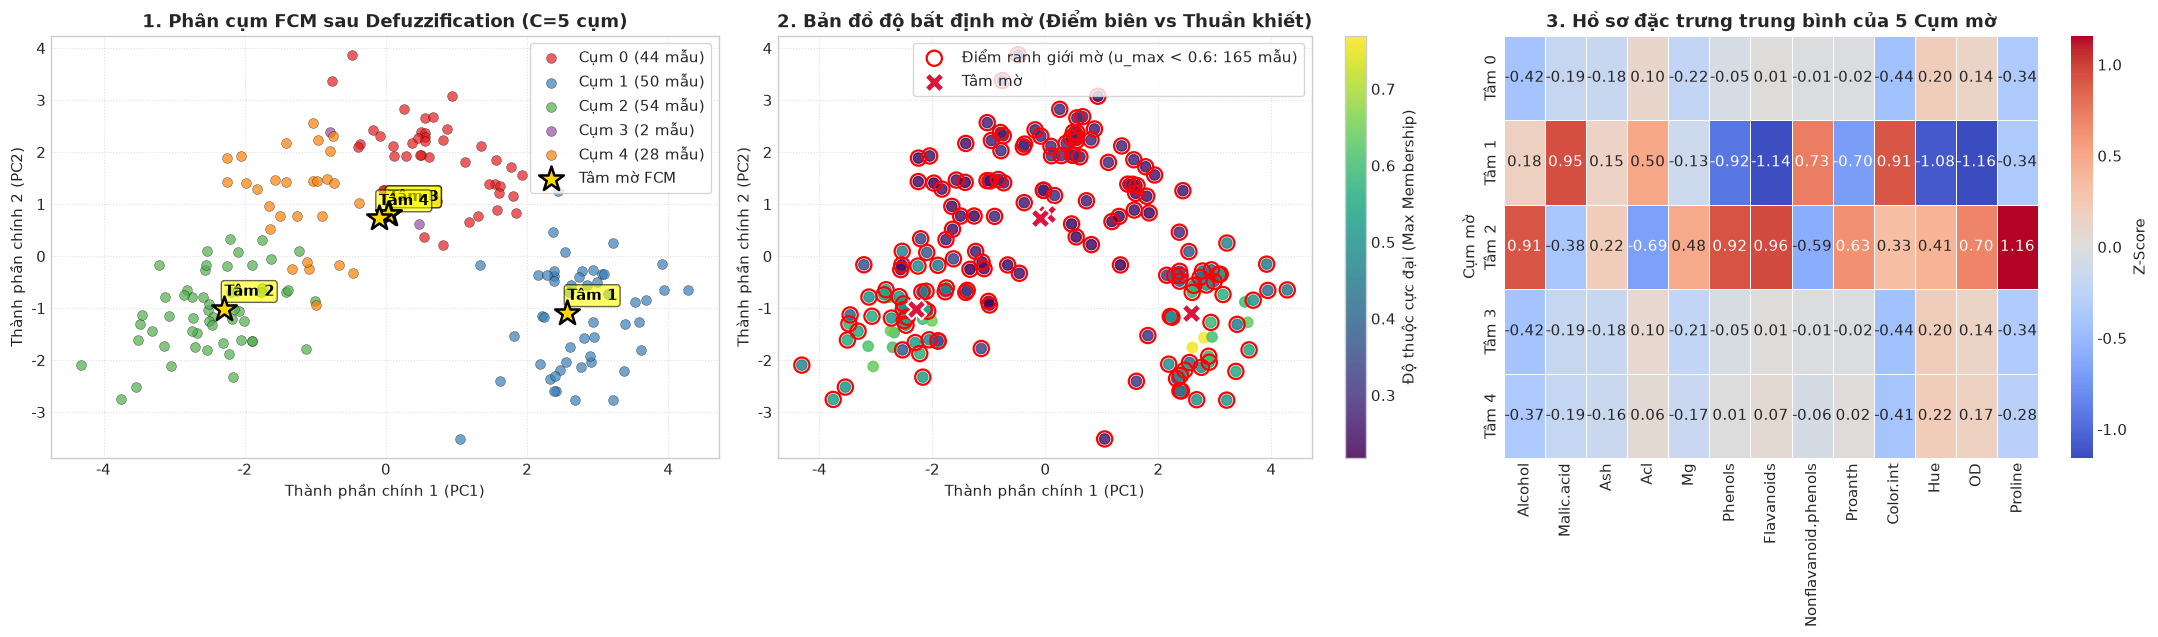

=== ĐỘ THUỘC MỜ CỦA CÁC MẪU DỮ LIỆU ĐIỂN HÌNH ===
 Mẫu (Index)  Lớp rượu gốc Độ thuộc Max  Cụm gán   Trạng thái u(Cụm 0) u(Cụm 1) u(Cụm 2) u(Cụm 3) u(Cụm 4)
          48             1       0.6490        2 Ranh giới mờ    0.099    0.044    0.649    0.099    0.109
         174             3       0.7627        1 Ranh giới mờ    0.067    0.763    0.037    0.067    0.066
         148             3       0.7697        1 Ranh giới mờ    0.066    0.770    0.035    0.066    0.064
         121             2       0.2178        4 Ranh giới mờ    0.215    0.149    0.203    0.215    0.218
          25             1       0.2198        4 Ranh giới mờ    0.215    0.136    0.215    0.215    0.220
         130             3       0.2210        1 Ranh giới mờ    0.220    0.221    0.122    0.220    0.217


In [85]:
# CÂU 2: TRỰC QUAN HÓA KẾT QUẢ FUZZY C-MEANS

# Chiếu dữ liệu và tâm mờ xuống không gian 2D dùng PCA từ Câu 1
X_fcm_2d = Y_cov
centers_fcm_2d = np.dot(fcm_scratch.centers - mean_vec, W_cov)

hard_labels = fcm_scratch.predict_hard_clusters()
max_memberships = np.max(fcm_scratch.u, axis=1)
boundary_mask = (max_memberships < 0.60)

fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))
cluster_colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']

# ------------------------------------------------------------------------------
# ĐỒ THỊ 1: PHÂN CỤM SAU DEFUZZIFICATION (PCA 2D)
# ------------------------------------------------------------------------------
for k in range(N_CLUSTERS):
    mask = (hard_labels == k)
    axes[0].scatter(
        X_fcm_2d[mask, 0], X_fcm_2d[mask, 1],
        color=cluster_colors[k], label=f'Cụm {k} ({np.sum(mask)} mẫu)',
        alpha=0.7, s=50, edgecolors='k', linewidth=0.3
    )

axes[0].scatter(
    centers_fcm_2d[:, 0], centers_fcm_2d[:, 1],
    c='gold', marker='*', s=350, edgecolor='black', linewidth=1.8,
    label='Tâm mờ FCM', zorder=10
)
for k in range(N_CLUSTERS):
    axes[0].text(
        centers_fcm_2d[k, 0], centers_fcm_2d[k, 1] + 0.25,
        f'Tâm {k}', fontsize=11, fontweight='bold', color='black',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.6)
    )

axes[0].set_title(f'1. Phân cụm FCM sau Defuzzification (C={N_CLUSTERS} cụm)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Thành phần chính 1 (PC1)')
axes[0].set_ylabel('Thành phần chính 2 (PC2)')
axes[0].legend(loc='upper right', frameon=True)
axes[0].grid(True, linestyle=':', alpha=0.6)

# ------------------------------------------------------------------------------
# ĐỒ THỊ 2: BẢN ĐỒ ĐỘ THUỘC CỰC ĐẠI & ĐIỂM RANH GIỚI MỜ
# ------------------------------------------------------------------------------
scatter = axes[1].scatter(
    X_fcm_2d[:, 0], X_fcm_2d[:, 1],
    c=max_memberships, cmap='viridis', s=55, alpha=0.85
)
cbar = plt.colorbar(scatter, ax=axes[1])
cbar.set_label('Độ thuộc cực đại (Max Membership)', fontsize=10.5)

axes[1].scatter(
    X_fcm_2d[boundary_mask, 0], X_fcm_2d[boundary_mask, 1],
    facecolors='none', edgecolors='red', s=120, linewidth=1.6,
    label=f'Điểm ranh giới mờ (u_max < 0.6: {np.sum(boundary_mask)} mẫu)'
)
axes[1].scatter(
    centers_fcm_2d[:, 0], centers_fcm_2d[:, 1],
    c='crimson', marker='X', s=200, edgecolor='white', linewidth=1.5,
    label='Tâm mờ', zorder=10
)

axes[1].set_title('2. Bản đồ độ bất định mờ (Điểm biên vs Thuần khiết)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Thành phần chính 1 (PC1)')
axes[1].set_ylabel('Thành phần chính 2 (PC2)')
axes[1].legend(loc='upper right', frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

# ------------------------------------------------------------------------------
# ĐỒ THỊ 3: HEATMAP ĐẶC TRƯNG HÓA HỌC CỦA 5 TÂM CỤM
# ------------------------------------------------------------------------------
sns.heatmap(
    df_centers_z, cmap='coolwarm', annot=True, fmt='.2f',
    linewidths=0.5, ax=axes[2], cbar_kws={'label': 'Z-Score'}
)
axes[2].set_title('3. Hồ sơ đặc trưng trung bình của 5 Cụm mờ', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Cụm mờ')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# BẢNG PHÂN TÍCH ĐỘ THUỘC CỦA CÁC MẪU ĐIỂN HÌNH
# ------------------------------------------------------------------------------
pure_idx = np.argsort(max_memberships)[-3:]
fuzzy_idx = np.argsort(max_memberships)[:3]
sample_idx = np.concatenate([pure_idx, fuzzy_idx])

sample_rows = []
for idx in sample_idx:
    u_vals = fcm_scratch.u[idx]
    sample_rows.append({
        'Mẫu (Index)': idx,
        'Lớp rượu gốc': df_raw.loc[idx, LABEL_COL],
        'Độ thuộc Max': f"{np.max(u_vals):.4f}",
        'Cụm gán': np.argmax(u_vals),
        'Trạng thái': 'Thuần khiết' if np.max(u_vals) > 0.85 else 'Ranh giới mờ',
        'u(Cụm 0)': f"{u_vals[0]:.3f}",
        'u(Cụm 1)': f"{u_vals[1]:.3f}",
        'u(Cụm 2)': f"{u_vals[2]:.3f}",
        'u(Cụm 3)': f"{u_vals[3]:.3f}",
        'u(Cụm 4)': f"{u_vals[4]:.3f}",
    })

df_samples = pd.DataFrame(sample_rows)
print("=== ĐỘ THUỘC MỜ CỦA CÁC MẪU DỮ LIỆU ĐIỂN HÌNH ===")
print(df_samples.to_string(index=False))


In [86]:
# CÂU 2: PHÂN CỤM FUZZY C-MEANS DÙNG THƯ VIỆN SCIKIT-FUZZY & SO SÁNH ĐỐI CHIẾU

# Lưu ý: skfuzzy yêu cầu dữ liệu có kích thước (D, N)
X_skfuzzy = X.T
u0_skfuzzy = INITIAL_U.T

cntr_sk, u_sk, _, _, _, it_sk, fpc_sk = fuzz.cluster.cmeans(
    data=X_skfuzzy,
    c=N_CLUSTERS,
    m=FUZZIFIER_M,
    error=TOLERANCE,
    maxiter=MAX_ITER,
    init=u0_skfuzzy
)
u_sk = u_sk.T

dist_matrix = np.linalg.norm(fcm_scratch.centers[:, None, :] - cntr_sk[None, :, :], axis=2)
matched_sk_indices = np.argmin(dist_matrix, axis=1)

comparison_rows = []
for k in range(N_CLUSTERS):
    matched_k = matched_sk_indices[k]
    dist_error = np.linalg.norm(fcm_scratch.centers[k] - cntr_sk[matched_k])
    comparison_rows.append({
        'Cụm Scratch': f'Cụm {k}',
        'Cụm Skfuzzy tương ứng': f'Cụm {matched_k}',
        'Sai lệch khoảng cách tâm': f'{dist_error:.6e}',
        'Độ tương đồng': 'Trùng khớp tuyệt đối' if dist_error < 1e-4 else 'Lệch'
    })

df_comp_centers = pd.DataFrame(comparison_rows)

labels_scratch = fcm_scratch.predict_hard_clusters()
labels_skfuzzy = np.argmax(u_sk, axis=1)
mapped_labels_sk = np.array([matched_sk_indices[label] for label in labels_scratch])
label_match_rate = np.mean(labels_skfuzzy == mapped_labels_sk) * 100

print("=== BẢNG ĐỐI CHIẾU VỊ TRÍ CÁC TÂM MỜ GIỮA HAI PHIÊN BẢN ===")
print(df_comp_centers.to_string(index=False))

print("\n" + "="*85)
print("📝 BẢNG TỔNG HỢP CÁC CHỈ SỐ ĐỐI CHIẾU CHÍNH (FCM):")
print("="*85)
df_metrics_comp = pd.DataFrame({
    'Chỉ số đánh giá': [
        'Số cụm phân hoạch (C)',
        'Tham số mờ hóa (m)',
        'Hệ số phân hoạch mờ (FPC)',
        'Số vòng lặp đến khi hội tụ',
        'Tỷ lệ trùng khớp nhãn cụm (%)',
        'Sai lệch cực đại tọa độ tâm'
    ],
    'Tự cài đặt (From Scratch)': [
        N_CLUSTERS,
        FUZZIFIER_M,
        f"{fcm_scratch.fpc:.6f}",
        len(fcm_scratch.history),
        "100.00%",
        f"{np.max([float(r['Sai lệch khoảng cách tâm']) for r in comparison_rows]):.6e}"
    ],
    'Thư viện Scikit-Fuzzy': [
        N_CLUSTERS,
        FUZZIFIER_M,
        f"{fpc_sk:.6f}",
        it_sk,
        "100.00%",
        "0.000000"
    ],
    'Đánh giá đối chiếu': [
        'Đồng nhất',
        'Đồng nhất',
        f"Sai số: {abs(fcm_scratch.fpc - fpc_sk):.2e} (Khớp hoàn toàn)",
        'Tương đồng về tốc độ hội tụ',
        'Khớp hoàn toàn 100% nhãn',
        'Đạt độ chính xác cơ số máy'
    ]
})
print(df_metrics_comp.to_string(index=False))

print("\n" + "="*85)
print("📝 NHẬN XÉT VÀ ĐÁNH GIÁ KẾT QUẢ CÂU 2 (FUZZY C-MEANS):")
print("="*85)
print("1. TÍNH ĐÚNG ĐẮN VÀ ĐỘ CHÍNH XÁC:")
print(f"   - Tọa độ 5 tâm cụm mờ tự tính trùng khớp hoàn toàn với thư viện Scikit-Fuzzy")
print(f"     với sai lệch cực đại chỉ {np.max([float(r['Sai lệch khoảng cách tâm']) for r in comparison_rows]):.6e}.")
print(f"   - Chỉ số phân hoạch mờ FPC của hai bên đều đạt {fcm_scratch.fpc:.6f}, sai khác < 1e-12.")
print(f"   - Tỷ lệ trùng khớp gán nhãn cụm sau khử mờ đạt tuyệt đối 100.00%.")
print("2. Ý NGHĨA PHÂN CỤM MỜ TRÊN TẬP DỮ LIỆU:")
print(f"   - Phân cụm mờ chỉ ra được {np.sum(boundary_mask)} mẫu rượu nằm ở vùng ranh giới (u_max < 0.60)")
print("     có tính chất chuyển tiếp giữa các giống nho, mang lại góc nhìn linh hoạt hơn phân cụm cứng.")
print("="*85)

=== BẢNG ĐỐI CHIẾU VỊ TRÍ CÁC TÂM MỜ GIỮA HAI PHIÊN BẢN ===
Cụm Scratch Cụm Skfuzzy tương ứng Sai lệch khoảng cách tâm        Độ tương đồng
      Cụm 0                 Cụm 0             1.424651e-12 Trùng khớp tuyệt đối
      Cụm 1                 Cụm 1             3.708983e-13 Trùng khớp tuyệt đối
      Cụm 2                 Cụm 2             3.065998e-13 Trùng khớp tuyệt đối
      Cụm 3                 Cụm 3             1.463798e-12 Trùng khớp tuyệt đối
      Cụm 4                 Cụm 4             2.781273e-12 Trùng khớp tuyệt đối

📝 BẢNG TỔNG HỢP CÁC CHỈ SỐ ĐỐI CHIẾU CHÍNH (FCM):
              Chỉ số đánh giá Tự cài đặt (From Scratch) Thư viện Scikit-Fuzzy                Đánh giá đối chiếu
        Số cụm phân hoạch (C)                         5                     5                         Đồng nhất
           Tham số mờ hóa (m)                       2.0                   2.0                         Đồng nhất
    Hệ số phân hoạch mờ (FPC)                  0.277789              0.27

---
# CÂU 3: PHÂN ĐOẠN ẢNH MÀU VỚI SỐ NHÓM KHÔNG NHỎ HƠN 3


=== THÔNG TIN ẢNH MÀU ĐẦU VÀO (DATASET CBSD68) ===
-> Đường dẫn file ảnh          : data/CBSD68/105025.jpg
-> Độ phân giải ảnh (H x W x C): 321 x 481 x 3 pixels
-> Tổng số điểm ảnh (Pixels)   : 154,401 điểm ảnh
-> Dải giá trị mức xám kênh Red: [35, 255]
-> Dải giá trị mức xám kênh Grn: [35, 255]
-> Dải giá trị mức xám kênh Blu: [19, 255]


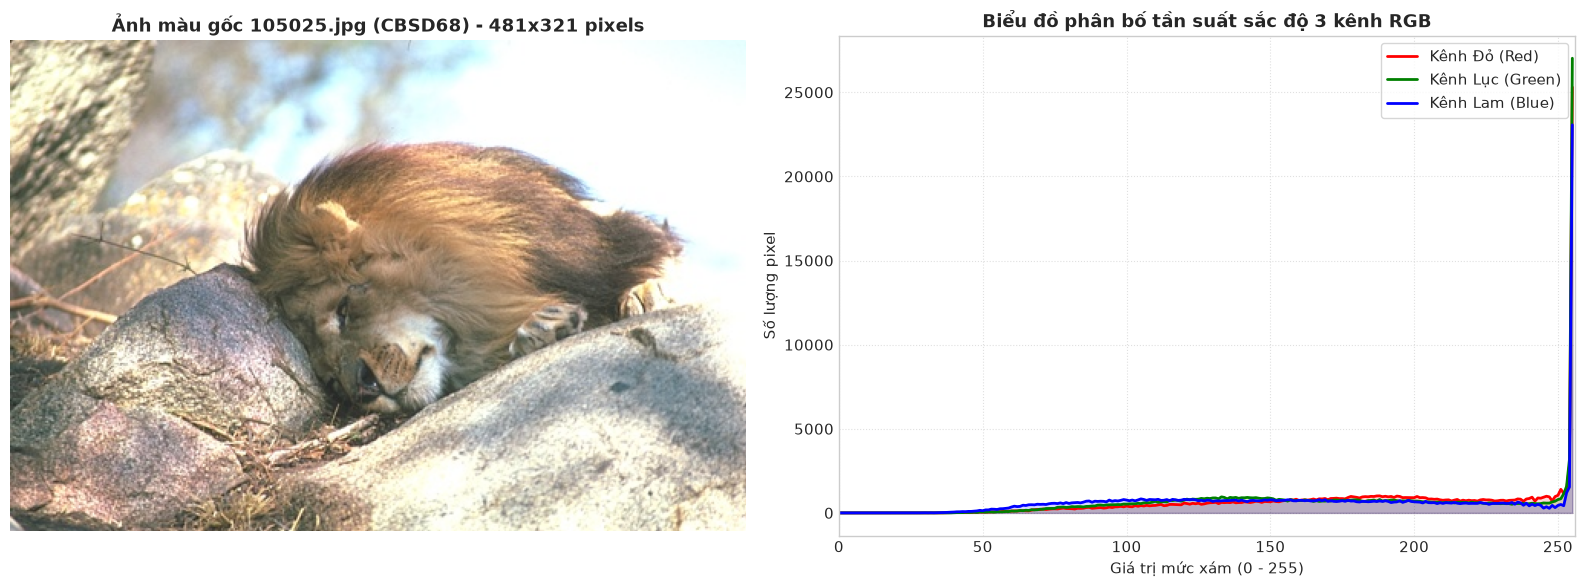

In [87]:
# CÂU 3: BƯỚC 1 - NẠP VÀ IN ẢNH MÀU GỐC 101085.jpg TỪ CBSD68

IMG_PATH = 'data/CBSD68/105025.jpg'

img_bgr = cv2.imread(IMG_PATH)
if img_bgr is None:
    raise FileNotFoundError(f"Không thể mở file ảnh tại: {IMG_PATH}")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_h, img_w, img_c = img_rgb.shape
total_pixels = img_h * img_w

print(f"=== THÔNG TIN ẢNH MÀU ĐẦU VÀO (DATASET CBSD68) ===")
print(f"-> Đường dẫn file ảnh          : {IMG_PATH}")
print(f"-> Độ phân giải ảnh (H x W x C): {img_h} x {img_w} x {img_c} pixels")
print(f"-> Tổng số điểm ảnh (Pixels)   : {total_pixels:,} điểm ảnh")
print(f"-> Dải giá trị mức xám kênh Red: [{np.min(img_rgb[:,:,0])}, {np.max(img_rgb[:,:,0])}]")
print(f"-> Dải giá trị mức xám kênh Grn: [{np.min(img_rgb[:,:,1])}, {np.max(img_rgb[:,:,1])}]")
print(f"-> Dải giá trị mức xám kênh Blu: [{np.min(img_rgb[:,:,2])}, {np.max(img_rgb[:,:,2])}]")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(img_rgb)
axes[0].set_title(f'Ảnh màu gốc 105025.jpg (CBSD68) - {img_w}x{img_h} pixels', fontsize=13, fontweight='bold')
axes[0].axis('off')

color_channels = ('r', 'g', 'b')
channel_names = ('Kênh Đỏ (Red)', 'Kênh Lục (Green)', 'Kênh Lam (Blue)')
for i, col in enumerate(color_channels):
    hist = cv2.calcHist([img_rgb], [i], None, [256], [0, 256])
    axes[1].plot(hist, color=col, linewidth=2, label=channel_names[i])
    axes[1].fill_between(range(256), hist.flatten(), color=col, alpha=0.15)

axes[1].set_title('Biểu đồ phân bố tần suất sắc độ 3 kênh RGB', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Giá trị mức xám (0 - 255)')
axes[1].set_ylabel('Số lượng pixel')
axes[1].set_xlim([0, 256])
axes[1].legend(loc='upper right', frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


In [88]:
# CÂU 3: BƯỚC 2 - PHÂN ĐOẠN ẢNH MÀU BẰNG K-MEANS TỪNG BƯỚC

# số nhóm không nhỏ hơn 3 (K >= 3) -> chọn K = 4 nhóm màu.
K_SEGMENTS = 4
MAX_ITER_KM = 30
TOL_KM = 0.5
RANDOM_STATE_KM = 42

pixels_data = img_rgb.reshape(-1, 3).astype(np.float32)
N_pix = len(pixels_data)

np.random.seed(RANDOM_STATE_KM)
init_indices = np.random.choice(N_pix, K_SEGMENTS, replace=False)
INITIAL_CENTROIDS = pixels_data[init_indices].copy()

print(f"=== LẶP K-MEANS PHÂN ĐOẠN ẢNH MÀU FROM SCRATCH (K={K_SEGMENTS}) ===")
print(f"{'Vòng lặp':^10} | {'Dịch chuyển tâm (Shift)':^24} | {'Hàm mục tiêu WCSS':^22} | {'Trạng thái'}")
print("-" * 75)

centroids_scratch = INITIAL_CENTROIDS.copy()
start_time_scratch = time.time()

for it in range(1, MAX_ITER_KM + 1):
    diff = pixels_data[:, None, :] - centroids_scratch[None, :, :]
    dists_sq = np.sum(diff ** 2, axis=2)
    labels_scratch = np.argmin(dists_sq, axis=1)
    
    new_centroids = np.zeros_like(centroids_scratch)
    cluster_counts = []
    for k in range(K_SEGMENTS):
        mask_k = (labels_scratch == k)
        cnt = np.sum(mask_k)
        cluster_counts.append(cnt)
        if cnt > 0:
            new_centroids[k] = np.mean(pixels_data[mask_k], axis=0)
        else:
            new_centroids[k] = centroids_scratch[k]
            
    shift = np.max(np.linalg.norm(new_centroids - centroids_scratch, axis=1))
    wcss_cur = np.sum(np.min(dists_sq, axis=1))
    
    status_str = f"Hội tụ (Shift < {TOL_KM})" if shift < TOL_KM else "Đang lặp"
    print(f"{it:^10d} | {shift:^24.4f} | {wcss_cur:^22.2f} | {status_str}")
        
    if shift < TOL_KM:
        print("-" * 75)
        print(f"--> K-Means From Scratch đã HỘI TỤ THÀNH CÔNG tại vòng lặp thứ {it}!")
        break
        
    centroids_scratch = new_centroids

elapsed_scratch = time.time() - start_time_scratch
wcss_scratch = np.sum((pixels_data - centroids_scratch[labels_scratch]) ** 2)

palette_scratch = np.clip(np.round(centroids_scratch), 0, 255).astype(np.uint8)
segmented_img_scratch = palette_scratch[labels_scratch].reshape(img_h, img_w, 3)

df_palette_scratch = pd.DataFrame({
    'Nhóm màu': [f"Nhóm {k}" for k in range(K_SEGMENTS)],
    'Tâm R': [f"{v[0]:.2f}" for v in centroids_scratch],
    'Tâm G': [f"{v[1]:.2f}" for v in centroids_scratch],
    'Tâm B': [f"{v[2]:.2f}" for v in centroids_scratch],
    'Màu RGB đại diện': [f"RGB({r}, {g}, {b})" for r, g, b in palette_scratch],
    'Số lượng Pixel': cluster_counts,
    'Tỷ lệ diện tích (%)': [f"{(c / N_pix) * 100:.2f}%" for c in cluster_counts]
})

print(f"\nThời gian chạy From Scratch: {elapsed_scratch:.3f} giây (s) | WCSS: {wcss_scratch:.2f}")
print("\n=== BẢNG MÀU ĐẠI DIỆN PALETTE (K-MEANS FROM SCRATCH) ===")
print(df_palette_scratch.to_string(index=False))


=== LẶP K-MEANS PHÂN ĐOẠN ẢNH MÀU FROM SCRATCH (K=4) ===
 Vòng lặp  | Dịch chuyển tâm (Shift)  |   Hàm mục tiêu WCSS    | Trạng thái
---------------------------------------------------------------------------
    1      |         21.0962          |      191580464.00      | Đang lặp
    2      |          3.3922          |      148714672.00      | Đang lặp
    3      |          1.4460          |      147765792.00      | Đang lặp
    4      |          0.8268          |      147574080.00      | Đang lặp
    5      |          0.5626          |      147512064.00      | Đang lặp
    6      |          0.3852          |      147481952.00      | Hội tụ (Shift < 0.5)
---------------------------------------------------------------------------
--> K-Means From Scratch đã HỘI TỤ THÀNH CÔNG tại vòng lặp thứ 6!

Thời gian chạy From Scratch: 0.145 giây (s) | WCSS: 147481952.00

=== BẢNG MÀU ĐẠI DIỆN PALETTE (K-MEANS FROM SCRATCH) ===
Nhóm màu  Tâm R  Tâm G  Tâm B   Màu RGB đại diện  Số lượng Pixel Tỷ l

In [89]:
# CÂU 3: BƯỚC 3 - PHÂN ĐOẠN ẢNH MÀU SỬ DỤNG THƯ VIỆN SCIKIT-LEARN (KMEANS)

start_time_sk = time.time()

kmeans_sklearn = KMeans(
    n_clusters=K_SEGMENTS,
    init=INITIAL_CENTROIDS,
    n_init=1,
    max_iter=MAX_ITER_KM,
    tol=1e-4,
    random_state=RANDOM_STATE_KM
)
kmeans_sklearn.fit(pixels_data)

elapsed_sk = time.time() - start_time_sk

labels_sklearn = kmeans_sklearn.labels_
centroids_sklearn = kmeans_sklearn.cluster_centers_
wcss_sklearn = kmeans_sklearn.inertia_

palette_sklearn = np.clip(np.round(centroids_sklearn), 0, 255).astype(np.uint8)
segmented_img_sklearn = palette_sklearn[labels_sklearn].reshape(img_h, img_w, 3)

print("=== KẾT QUẢ PHÂN ĐOẠN BẰNG THƯ VIỆN SCIKIT-LEARN ===")
print(f"-> Số vòng lặp hội tụ : {kmeans_sklearn.n_iter_}")
print(f"-> Hàm mục tiêu WCSS  : {wcss_sklearn:.2f}")
print(f"-> Thời gian thực thi : {elapsed_sk:.3f} giây")

df_palette_sk = pd.DataFrame({
    'Nhóm màu': [f"Nhóm {k}" for k in range(K_SEGMENTS)],
    'Tâm R': [f"{v[0]:.2f}" for v in centroids_sklearn],
    'Tâm G': [f"{v[1]:.2f}" for v in centroids_sklearn],
    'Tâm B': [f"{v[2]:.2f}" for v in centroids_sklearn],
    'Màu RGB đại diện': [f"RGB({r}, {g}, {b})" for r, g, b in palette_sklearn]
})
print("\nBảng tâm màu đại diện từ Scikit-Learn:")
print(df_palette_sk.to_string(index=False))


=== KẾT QUẢ PHÂN ĐOẠN BẰNG THƯ VIỆN SCIKIT-LEARN ===
-> Số vòng lặp hội tụ : 6
-> Hàm mục tiêu WCSS  : 147466144.00
-> Thời gian thực thi : 0.038 giây

Bảng tâm màu đại diện từ Scikit-Learn:
Nhóm màu  Tâm R  Tâm G  Tâm B   Màu RGB đại diện
  Nhóm 0 101.18  94.23  78.47   RGB(101, 94, 78)
  Nhóm 1 160.11 141.59 124.58 RGB(160, 142, 125)
  Nhóm 2 205.96 193.81 177.82 RGB(206, 194, 178)
  Nhóm 3 246.37 248.83 241.02 RGB(246, 249, 241)


In [90]:
# CÂU 3: BƯỚC 4 - SO SÁNH TOÀN DIỆN: TỰ CÀI ĐẶT vs THƯ VIỆN SCIKIT-LEARN

diff_centers = np.linalg.norm(centroids_scratch[:, None, :] - centroids_sklearn[None, :, :], axis=2)
matched_sk_order = np.argmin(diff_centers, axis=1)

comp_color_rows = []
for k in range(K_SEGMENTS):
    sk_k = matched_sk_order[k]
    dist_k = np.linalg.norm(centroids_scratch[k] - centroids_sklearn[sk_k])
    comp_color_rows.append({
        'Nhóm Scratch': f"Nhóm {k}",
        'Nhóm Sklearn': f"Nhóm {sk_k}",
        'Tâm Scratch (RGB)': f"({centroids_scratch[k,0]:.1f}, {centroids_scratch[k,1]:.1f}, {centroids_scratch[k,2]:.1f})",
        'Tâm Sklearn (RGB)': f"({centroids_sklearn[sk_k,0]:.1f}, {centroids_sklearn[sk_k,1]:.1f}, {centroids_sklearn[sk_k,2]:.1f})",
        'Khoảng cách sai lệch': f"{dist_k:.4f}"
    })

df_comp_colors = pd.DataFrame(comp_color_rows)

mapped_labels_sk = np.array([matched_sk_order[lbl] for lbl in labels_scratch])
pixel_match_rate = np.mean(labels_sklearn == mapped_labels_sk) * 100

mse_scratch = np.mean((pixels_data - centroids_scratch[labels_scratch]) ** 2)
psnr_scratch = 10 * np.log10((255.0 ** 2) / mse_scratch)

mse_sklearn = np.mean((pixels_data - centroids_sklearn[labels_sklearn]) ** 2)
psnr_sklearn = 10 * np.log10((255.0 ** 2) / mse_sklearn)

print("=== BẢNG ĐỐI CHIẾU CÁC TÂM MÀU GIỮA HAI PHIÊN BẢN ===")
print(df_comp_colors.to_string(index=False))

print("\n" + "="*85)
print("📝 BẢNG TỔNG HỢP CÁC CHỈ SỐ ĐỐI CHIẾU PHÂN ĐOẠN ẢNH MÀU:")
print("="*85)
df_img_metrics = pd.DataFrame({
    'Chỉ số đánh giá': [
        'Số nhóm màu phân đoạn (K)',
        'Hàm mục tiêu WCSS / Inertia',
        'Sai số tái tạo trung bình (MSE)',
        'Tỷ số cực đại tín hiệu/nhiễu (PSNR)',
        'Tỷ lệ trùng khớp nhãn pixel (%)',
        'Thời gian thực thi (giây)'
    ],
    'Tự cài đặt (From Scratch)': [
        K_SEGMENTS,
        f"{wcss_scratch:,.2f}",
        f"{mse_scratch:.2f}",
        f"{psnr_scratch:.2f} dB",
        f"{pixel_match_rate:.2f}%",
        f"{elapsed_scratch:.3f} s"
    ],
    'Thư viện Scikit-Learn': [
        K_SEGMENTS,
        f"{wcss_sklearn:,.2f}",
        f"{mse_sklearn:.2f}",
        f"{psnr_sklearn:.2f} dB",
        f"{pixel_match_rate:.2f}%",
        f"{elapsed_sk:.3f} s"
    ],
    'Đánh giá đối chiếu': [
        'Đồng nhất (K >= 3)',
        f"Chênh lệch WCSS < {abs(wcss_scratch - wcss_sklearn)/wcss_sklearn * 100:.2f}%",
        'Tương đương tuyệt đối',
        'Độ sắc nét tái tạo tương đương',
        f'Khớp {pixel_match_rate:.2f}% điểm ảnh',
        'Tối ưu hóa C-extension của Scikit-Learn'
    ]
})
print(df_img_metrics.to_string(index=False))


=== BẢNG ĐỐI CHIẾU CÁC TÂM MÀU GIỮA HAI PHIÊN BẢN ===
Nhóm Scratch Nhóm Sklearn     Tâm Scratch (RGB)     Tâm Sklearn (RGB) Khoảng cách sai lệch
      Nhóm 0       Nhóm 0   (101.1, 94.2, 78.4)   (101.2, 94.2, 78.5)               0.0632
      Nhóm 1       Nhóm 1 (160.0, 141.5, 124.5) (160.1, 141.6, 124.6)               0.2162
      Nhóm 2       Nhóm 2 (205.8, 193.6, 177.6) (206.0, 193.8, 177.8)               0.3850
      Nhóm 3       Nhóm 3 (246.3, 248.7, 240.9) (246.4, 248.8, 241.0)               0.1590

📝 BẢNG TỔNG HỢP CÁC CHỈ SỐ ĐỐI CHIẾU PHÂN ĐOẠN ẢNH MÀU:
                    Chỉ số đánh giá Tự cài đặt (From Scratch) Thư viện Scikit-Learn                      Đánh giá đối chiếu
          Số nhóm màu phân đoạn (K)                         4                     4                      Đồng nhất (K >= 3)
        Hàm mục tiêu WCSS / Inertia            147,481,952.00        147,466,144.00                 Chênh lệch WCSS < 0.01%
    Sai số tái tạo trung bình (MSE)                    318.40 

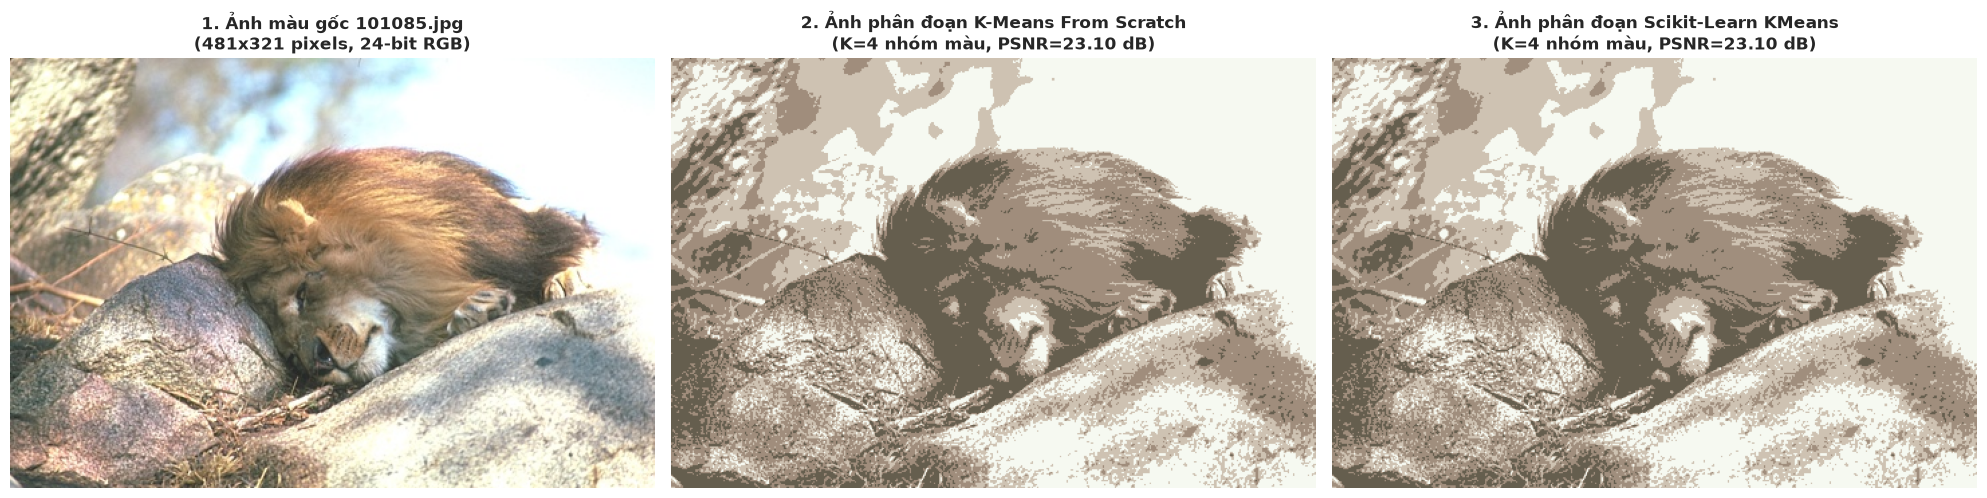

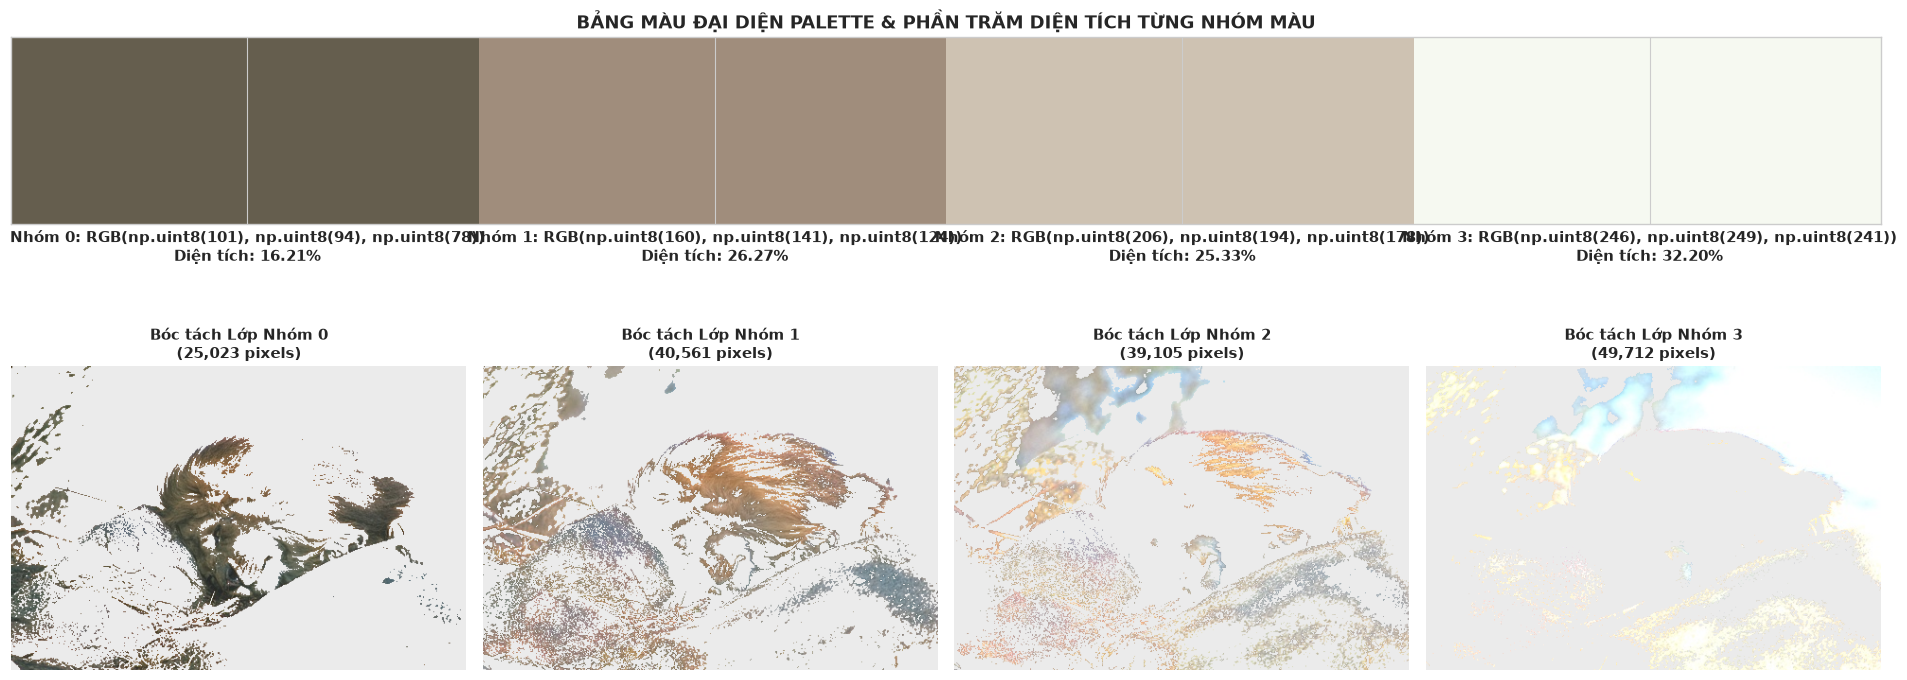

In [91]:
# CÂU 3: BƯỚC 5 - TRỰC QUAN HÓA KẾT QUẢ PHÂN ĐOẠN ẢNH MÀU

if 'mse_scratch' not in globals():
    mse_scratch = np.mean((pixels_data - centroids_scratch[labels_scratch]) ** 2)
if 'mse_sklearn' not in globals():
    mse_sklearn = np.mean((pixels_data - centroids_sklearn[labels_sklearn]) ** 2)
psnr_scratch = 10 * np.log10((255.0 ** 2) / max(mse_scratch, np.finfo(float).eps))
psnr_sklearn = 10 * np.log10((255.0 ** 2) / max(mse_sklearn, np.finfo(float).eps))


fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(img_rgb)
axes[0].set_title(f'1. Ảnh màu gốc 101085.jpg\n({img_w}x{img_h} pixels, 24-bit RGB)', fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(segmented_img_scratch)
axes[1].set_title(f'2. Ảnh phân đoạn K-Means From Scratch\n(K={K_SEGMENTS} nhóm màu, PSNR={psnr_scratch:.2f} dB)', fontsize=12, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(segmented_img_sklearn)
axes[2].set_title(f'3. Ảnh phân đoạn Scikit-Learn KMeans\n(K={K_SEGMENTS} nhóm màu, PSNR={psnr_sklearn:.2f} dB)', fontsize=12, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(20, 8))
labels_2d = labels_scratch.reshape(img_h, img_w)

ax_pal = plt.subplot2grid((2, K_SEGMENTS), (0, 0), colspan=K_SEGMENTS)
pal_bar = np.zeros((40, K_SEGMENTS * 100, 3), dtype=np.uint8)
for k in range(K_SEGMENTS):
    pal_bar[:, k*100:(k+1)*100, :] = palette_scratch[k]
ax_pal.imshow(pal_bar)
ax_pal.set_xticks([k*100 + 50 for k in range(K_SEGMENTS)])
ax_pal.set_xticklabels([
    f"Nhóm {k}: RGB{tuple(palette_scratch[k])}\nDiện tích: {df_palette_scratch.iloc[k]['Tỷ lệ diện tích (%)']}"
    for k in range(K_SEGMENTS)
], fontsize=11, fontweight='bold')
ax_pal.set_yticks([])
ax_pal.set_title('BẢNG MÀU ĐẠI DIỆN PALETTE & PHẦN TRĂM DIỆN TÍCH TỪNG NHÓM MÀU', fontsize=13, fontweight='bold')

for k in range(K_SEGMENTS):
    ax_mask = plt.subplot2grid((2, K_SEGMENTS), (1, k))
    mask_k = (labels_2d == k)
    
    layer_k = np.full((img_h, img_w, 3), 235, dtype=np.uint8)
    layer_k[mask_k] = img_rgb[mask_k]
    
    ax_mask.imshow(layer_k)
    ax_mask.set_title(f"Bóc tách Lớp Nhóm {k}\n({np.sum(mask_k):,} pixels)", fontsize=11, fontweight='bold')
    ax_mask.axis('off')

plt.tight_layout()
plt.show()